# Carga de dataset y librerias

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd 
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "viral_songs.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "vedauv/what-makes-a-song-go-viral-10000-tracks",
    file_path,
)

print(df.shape)
df.head()

(10000, 17)


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [14]:
df.dtypes

track_id             object
track_name           object
artist               object
genre                object
release_year          int64
duration_sec          int64
danceability        float64
energy              float64
valence             float64
tempo_bpm           float64
acousticness        float64
instrumentalness    float64
speechiness         float64
liveness            float64
loudness_db         float64
streams               int64
viral                 int64
dtype: object

## Agrupación de variables

In [15]:
numericas= ["release_year", "duration_sec", "danceability", "energy", "valence", "tempo_bpm", "acousticness", "instrumentalness", "speechiness", "liveness", "loudness_db", "streams"]
target= ["viral"]
categoricas = ["artist", "genre"]

canciones = df[numericas + categoricas + target]
canciones.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
release_year,10000.0,2017.5,4.6,2010.0,2013.0,2018.0,2022.0,2025.0
duration_sec,10000.0,208.8,50.0,60.0,175.0,209.0,242.0,433.0
danceability,10000.0,0.6,0.2,0.0,0.5,0.6,0.8,1.0
energy,10000.0,0.7,0.2,0.0,0.5,0.7,0.8,1.0
valence,10000.0,0.6,0.2,0.0,0.5,0.6,0.7,1.0
tempo_bpm,10000.0,111.0,19.0,50.0,98.0,111.3,124.5,177.8
acousticness,10000.0,0.3,0.3,0.0,0.1,0.2,0.4,1.0
instrumentalness,10000.0,0.2,0.2,0.0,0.0,0.2,0.3,0.9
speechiness,10000.0,0.1,0.1,0.0,0.0,0.1,0.1,0.4
liveness,10000.0,0.2,0.1,0.0,0.1,0.2,0.3,0.6


## Creación de kpis 

In [16]:
Kpis = {
    "Canciones totales" : len(df),
    "Duración primedio_sec" : df["duration_sec"].mean(),
    "Mayor reproducción": df["streams"].max(),
    "Año mas viral": df.groupby("release_year")["viral"].sum().idxmax(),
    "Cantidad de generos": df["genre"].nunique(),
    "Artistas únicos" : df["artist"].nunique(),
    "Canciones virales (%)" : df["viral"].mean()*100
      }

for nombre, valor in Kpis.items():
    print(f"{nombre:<30}{valor:>10,.0f}")

Canciones totales                 10,000
Duración primedio_sec                209
Mayor reproducción            443,068,342
Año mas viral                      2,014
Cantidad de generos                   10
Artistas únicos                    1,987
Canciones virales (%)                 36


## Analisis de variable objetivo 


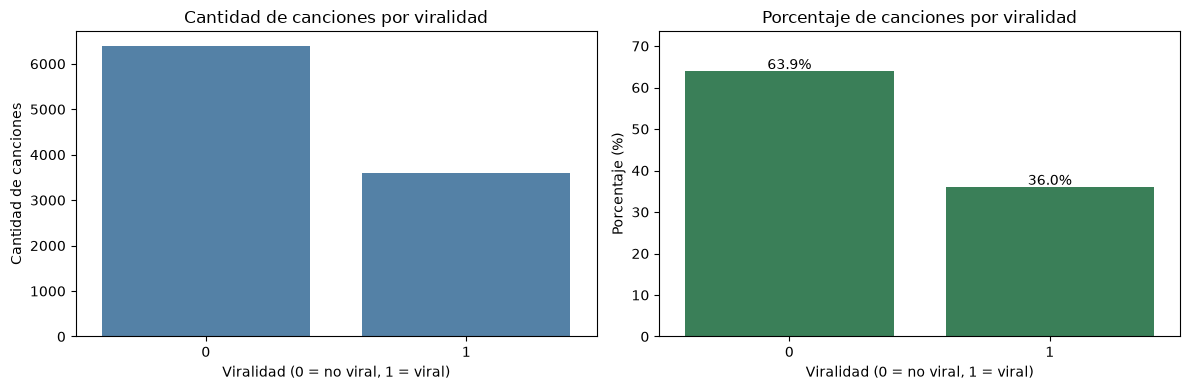

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: conteo
sns.countplot(data= df, x= df["viral"], order=[0, 1], color="steelblue", ax=axes[0])
axes[0].set(
    title="Cantidad de canciones por viralidad",
    xlabel="Viralidad (0 = no viral, 1 = viral)",
    ylabel="Cantidad de canciones"
)

# Gráfico 2: porcentaje
proporciones = df["viral"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

sns.barplot(x=proporciones.index, y=proporciones.values, color="seagreen", ax=axes[1])
axes[1].set(
    title="Porcentaje de canciones por viralidad",
    xlabel="Viralidad (0 = no viral, 1 = viral)",
    ylabel="Porcentaje (%)"
)

for i, valor in enumerate(proporciones.values):
    axes[1].text(i, valor + 0.5, f"{valor:.1f}%", ha="center")

axes[1].set_ylim(0, max(proporciones) * 1.15)

plt.tight_layout()
plt.show()

## Analisis univariado 


### Númericas

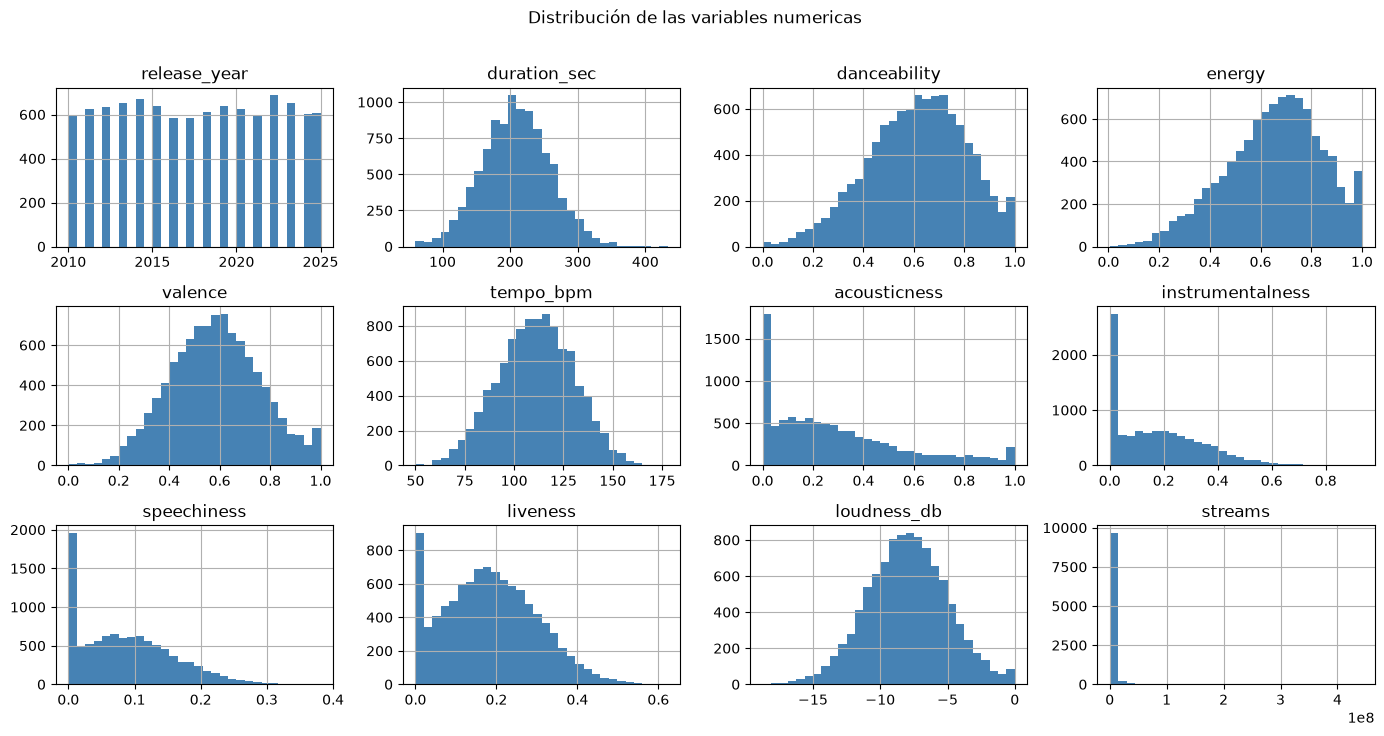

In [18]:
canciones[numericas].hist(bins = 30 , figsize= (14,9), layout= (4,4), color= "steelblue")
plt.suptitle("Distribución de las variables numericas", y = 1.01)
plt.tight_layout()
plt.show()

### Caterogicas


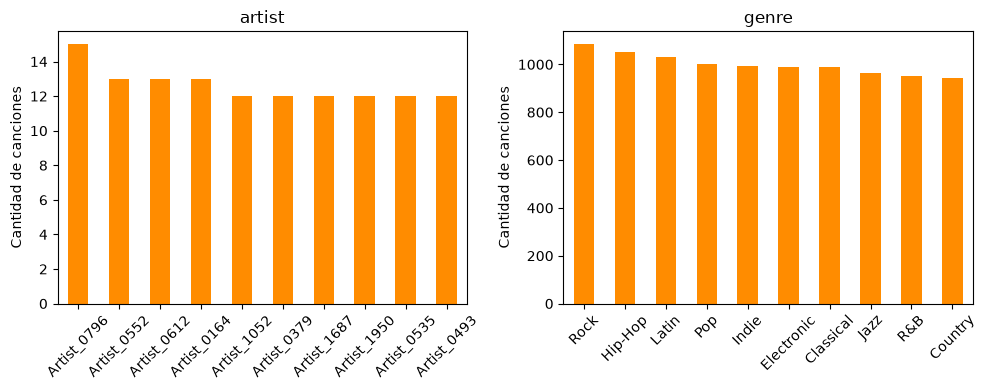

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, categoricas):
    if col in ["artist", "genre"]:
        frecuencias = df[col].value_counts().head(10)
    else:
        frecuencias = df[col].value_counts()
    frecuencias.plot(kind="bar",ax=ax,color="darkorange")
    ax.set(title=col, xlabel="", ylabel="Cantidad de canciones")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 3. Análisis bivariado:

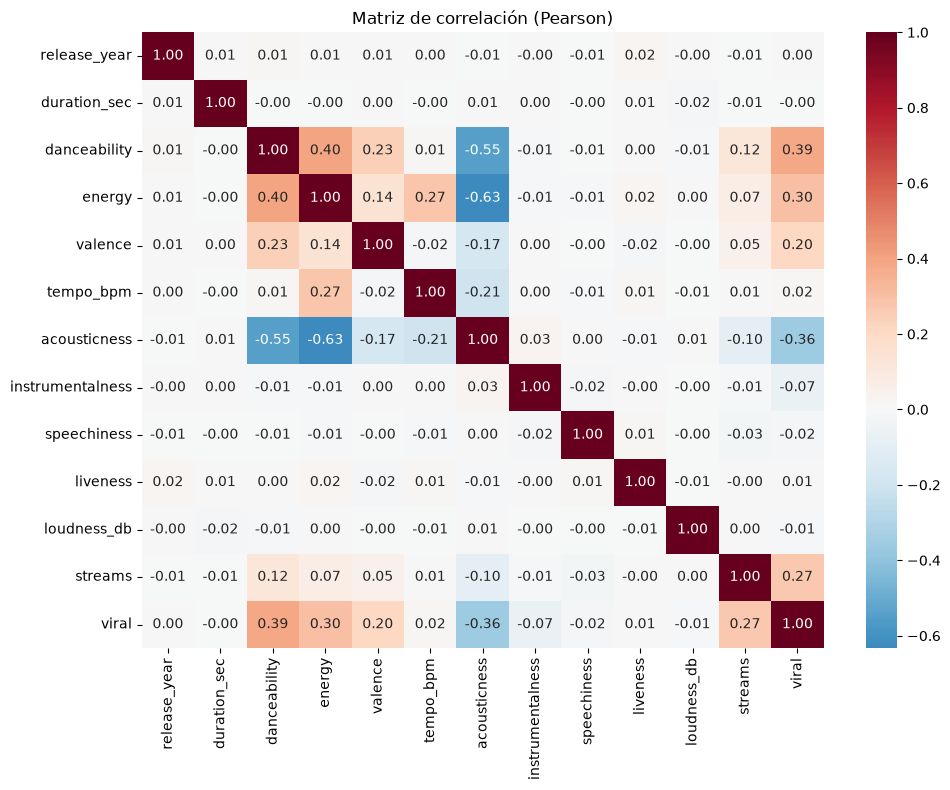

In [20]:
plt.figure(figsize=(11, 8))

sns.heatmap(df[numericas + target].corr(),annot=True,fmt=".2f",cmap="RdBu_r",center=0)
plt.title("Matriz de correlación (Pearson)")
plt.show()

In [22]:
def correlaciones_con_target(df, target):
    return (df.select_dtypes(include="number").corr()[target].drop(target).sort_values(ascending=False))
correlaciones_con_target(df, "viral").to_frame("r_con_viral").round(2)

,r_con_viral
danceability,0.39
energy,0.30
streams,0.27
valence,0.20
tempo_bpm,0.02
liveness,0.01
release_year,0.00
duration_sec,-0.00
loudness_db,-0.01
speechiness,-0.02


### 3.2 Numéricas vs. Viral

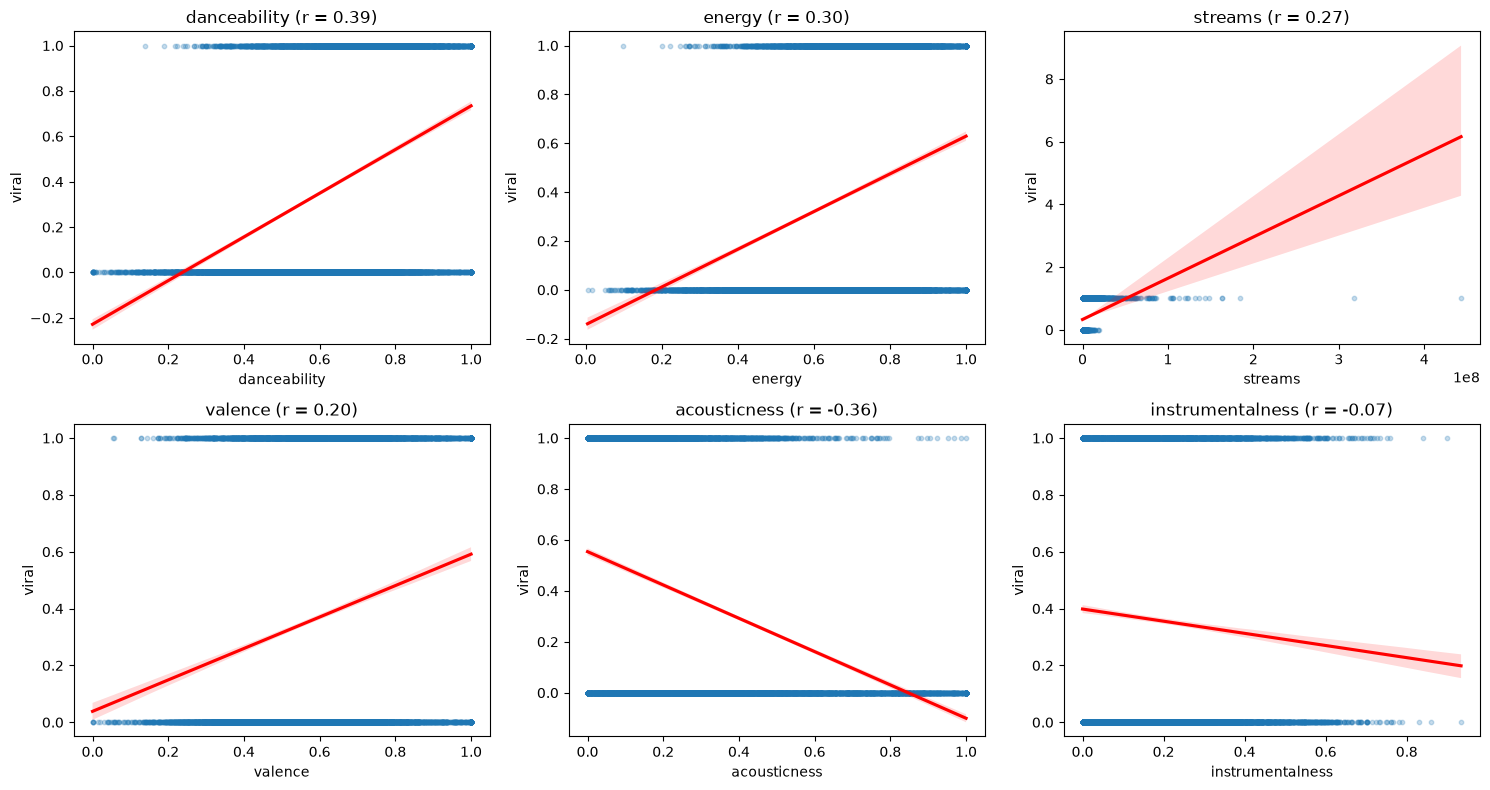

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), ["danceability", "energy", "streams", "valence", "acousticness", "instrumentalness"]):
    sns.regplot(data=df, x=col, y="viral", ax=ax, scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"})
    ax.set(title=f"{col} (r = {df[col].corr(df['viral']):.2f})")

plt.tight_layout()
plt.show()


### 3.3 Categóricas vs. Viral